




















# Atividade Prática 8

Aluno: João Gabriel Angelo Bradachi

Professor: Fabrício Silva

Objetivo: Aplicar auto-sklearn (ou outro AutoML) no dataset Churn_Bank.csv.csv e comparar os resultados com os anteriores. Fazer validação cruzada com separação em treino, validação e teste.

In [13]:
! pip install xgboost 
! pip install setuptools==81.0.0
! pip install pandas numpy matplotlib seaborn scipy scikit-learn
! pip install tpot
! pip install optuna

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
import tpot
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from time import time
import optuna
from sklearn.metrics import RocCurveDisplay

# Churn Bank

Aqui vou pular o processo de análise exploratória dos dados pois já foi feita na atividade 3. Primeiramente irei retomar os resultados obtidos na atv3 e posteriormente irei usar o tpot e comparar os resultados

## XGB com engenharia de dados do próprio aluno (feita na atividade 3) e ajuste de hiper parametros com optuna

In [10]:
churn_raw = pd.read_csv("Churn_Bank.csv")
churn_raw

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


## Análise prévia dos dados
* algumas colunas são booleanas, HasCrCard, IsActiveMember, Exited
* Tenure e num of products podem ser categóricas 
* podemos colocar balance, age, creditScore e EstimatedSalary em bins
* podemos remover RowNumber e CostumerID
* podemos criar uma categoria a mais no surname juntando todos os sobrenomes que aparecem apenas uma vez (chamar de "outros")

Mas vamos tentar fazer a previsão usando o dataset todo sem nenhuma engenharia de dados. Vamos usar o XGBoost

## Melhorando a partir dos atributos numéricos

In [20]:
df_tratado = churn_raw.drop(columns=['CustomerId', 'RowNumber'])

df_tratado['Surname'] = df_tratado['Surname'].astype('str')      
df_tratado['CreditScore'] = df_tratado['CreditScore'].astype('int64')    
df_tratado['Geography'] = df_tratado['Geography'].astype('str')      
df_tratado['Gender'] = df_tratado['Gender'].astype('str')      
df_tratado['Age'] = df_tratado['Age'].astype('int64')    
df_tratado['Tenure'] = df_tratado['Tenure'].astype('int64')    
df_tratado['Balance'] = df_tratado['Balance'].astype('float64')  
df_tratado['NumOfProducts'] = df_tratado['NumOfProducts'].astype('str')    
df_tratado['HasCrCard'] = df_tratado['HasCrCard'].astype('bool')    
df_tratado['IsActiveMember'] = df_tratado['IsActiveMember'].astype('bool')    
df_tratado['EstimatedSalary'] = df_tratado['EstimatedSalary'].astype('float64')  
df_tratado['Exited'] = df_tratado['Exited'].astype('bool')

df_tratado.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Surname          10000 non-null  str    
 1   CreditScore      10000 non-null  int64  
 2   Geography        10000 non-null  str    
 3   Gender           10000 non-null  str    
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  str    
 8   HasCrCard        10000 non-null  bool   
 9   IsActiveMember   10000 non-null  bool   
 10  EstimatedSalary  10000 non-null  float64
 11  Exited           10000 non-null  bool   
dtypes: bool(3), float64(2), int64(3), str(4)
memory usage: 732.6 KB


In [21]:
# vamos aplicar o binning em balance, age, creditScore e EstimatedSalary

df_tratado['Age_bin'] = pd.qcut(df_tratado['Age'], q=10, labels=False)

# df_tratado['Balance_bin'] = pd.qcut(df_tratado['Balance'], q=20, labels=False, duplicates='drop')

df_tratado['CreditScore_bin'] = pd.qcut(df_tratado['CreditScore'], q=20, labels=False)

# df_tratado['EstimatedSalary_bin'] = pd.qcut(df_tratado['EstimatedSalary'], q=20, labels=False, duplicates='drop')

df_tratado['Tenure_bin'] = pd.qcut(df_tratado['Tenure'], q=5, labels=False, duplicates='drop')

df_tratado


,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_bin,CreditScore_bin,Tenure_bin
0,Hargrave,619,France,Female,42,2,0.00,1,True,True,101348.88,True,6,7,0
1,Hill,608,Spain,Female,41,1,83807.86,1,False,True,112542.58,False,6,6,0
2,Onio,502,France,Female,42,8,159660.80,3,True,False,113931.57,True,6,1,3
3,Boni,699,France,Female,39,1,0.00,2,False,False,93826.63,False,5,13,0
4,Mitchell,850,Spain,Female,43,2,125510.82,1,True,True,79084.10,False,7,19,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Obijiaku,771,France,Male,39,5,0.00,2,True,False,96270.64,False,5,17,2
9996,Johnstone,516,France,Male,35,10,57369.61,1,True,True,101699.77,False,3,1,4
9997,Liu,709,France,Female,36,7,0.00,1,False,True,42085.58,True,4,14,3
9998,Sabbatini,772,Germany,Male,42,3,75075.31,2,True,False,92888.52,True,6,17,1


In [43]:
colunas_xgb_to_get = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', "Age_bin", 'Balance', 'CreditScore_bin', 'EstimatedSalary']
colunas_tpot_to_drop = ['Age_bin', 'CreditScore_bin', 'Tenure_bin']

X = df_tratado.drop('Exited', axis=1) 
y = df_tratado['Exited']              

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

X_treino_xgb = X_treino[colunas_xgb_to_get]
X_treino_tpot= X_treino.drop(columns=colunas_tpot_to_drop)

X_teste_xgb = X_teste[colunas_xgb_to_get]
X_teste_tpot= X_teste.drop(columns=colunas_tpot_to_drop)

scaler = StandardScaler()

colunas_padronizar = ['Balance', 'EstimatedSalary']

transformer_numerico = Pipeline(steps=[
    ('num_std', StandardScaler()),
])

# Pega o nome das colunas numéricas (int e float)
colunas_numericas = X_treino_xgb.select_dtypes(include=['int64', 'float64', 'number']).columns.tolist()

# Pega o nome das colunas categóricas (object/string)
colunas_categoricas = X_treino_xgb.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

# Pipeline para categorias: aplica One-Hot Encoding
transformer_categorico = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore')) # ignore: se aparecer uma categoria nova no teste, ele não quebra
])

# ColumnTransformer
pre_processador = ColumnTransformer(
    transformers=[
        ('cat', transformer_categorico, colunas_categoricas),
        ('num', transformer_numerico, colunas_padronizar)
    ])

In [ ]:
def objective(trial):
  params = {
      'n_estimators': trial.suggest_int('n_estimators', 50, 300),
      'max_depth': trial.suggest_int('max_depth', 3, 9),
      'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
      'subsample': trial.suggest_float('subsample', 0.5, 1.0),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
  }

  modelo_pipeline = Pipeline(steps=[
      ('pre_processamento', pre_processador),
      ('classificador', XGBClassifier(**params))
  ])
  
  scores = cross_val_score(modelo_pipeline, X_treino_xgb, y_treino, cv=5, scoring='accuracy', verbose=1)
  return scores.mean()


# Executando o estudo
start = time()
study_XGBoost = optuna.create_study(direction='maximize')

study_XGBoost.optimize(objective, n_trials=100)
print(f"Tempo para treinar 5 vezes com 5 cross validations: {time()-start} segundos")
print('Melhores parâmetros:', study_XGBoost.best_params)

[I 2026-10-18 15:37:16,947] A new study created in memory with name: no-name-2528dfb4-7ebd-449b-824c-c02084ba00a3
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.1s finished
[I 2026-10-18 15:37:18,068] Trial 0 finished with value: 0.81975 and parameters: {'n_estimators': 178, 'max_depth': 5, 'learning_rate': 0.023561259909351775, 'subsample': 0.5155641855048125, 'colsample_bytree': 0.9813361247976884}. Best is trial 0 with value: 0.81975.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.5s finished
[I 2026-10-18 15:37:19,551] Trial 1 finished with value: 0.814875 and parameters: {'n_estimators': 228, 'max_depth': 6, 'learning_rate': 0.043996472306367794, 'subsample': 0.579692892279809, 'colsample_bytree': 0.9345257424509104}. Best is trial 0 with value: 0.81975.
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.9s finished
[I 2026-10-18 15:37:20,428] Trial 2 finished with value: 0.8115 and parameters: {'n_estimators': 143, 'max_depth': 5, 'learning_rate': 0.1

Tempo para treinar 5 vezes com 5 cross validations: 254.62061166763306 segundos
Melhores parâmetros: {'n_estimators': 195, 'max_depth': 5, 'learning_rate': 0.021397444425742592, 'subsample': 0.5577272785273202, 'colsample_bytree': 0.9204517474485401}


In [44]:
# Validação para os melhores parâmetros:
melhores_parametros = {
    'n_estimators': 195, 'max_depth': 5, 'learning_rate': 0.021397444425742592, 
    'subsample': 0.5577272785273202, 'colsample_bytree': 0.9204517474485401
    }

modelo_pipeline = Pipeline(steps=[
      ('pre_processamento', pre_processador),
      # ('classificador', XGBClassifier(**study_XGBoost.best_params))
      ('classificador', XGBClassifier(**melhores_parametros))
  ])
modelo_pipeline.fit(X_treino_xgb, y_treino)

print("Fazendo previsões no conjunto de teste...")
previsoes = modelo_pipeline.predict(X_teste_xgb)

print("\nRelatório de Classificação:")
print(classification_report(y_teste, previsoes, digits=5))

Fazendo previsões no conjunto de teste...

Relatório de Classificação:
              precision    recall  f1-score   support

       False    0.83888   0.97200   0.90055      1607
        True    0.67391   0.23664   0.35028       393

    accuracy                        0.82750      2000
   macro avg    0.75640   0.60432   0.62542      2000
weighted avg    0.80647   0.82750   0.79242      2000



## TPOT

TPOT significa Tree-based Pipeline Optimization Tool (Ferramenta de Otimização de Pipelines Baseada em Árvores). TPOT é uma ferramenta de aprendizado de máquina automatizada em Python que otimiza pipelines de aprendizado de máquina usando programação genética.

Referência: [tpot github](https://github.com/epistasislab/tpot)

In [ ]:
# Vou usar primeiramente as configurações padrão do TPOT:
{
    "generations": 100, # int Número de iterações (gerações) para executar o processo de otimização evolutiva 
                        # do pipeline.

    "population_size": 100, # int Número de indivíduos (pipelines) mantidos na população a cada geração.

    "offspring_size": None, # int Número de "descendentes" (novos pipelines) gerados em cada ciclo evolutivo 
                            # (quando None, costuma assumir o mesmo valor de population_size).

    "mutation_rate": 0.9, # float entre 0.0 e 1.0, Taxa de mutação aplicada aos pipelines a cada geração.

    "crossover_rate": 0.1, # float entre 0.0 e 1.0, Taxa de cruzamento (recombinação) entre os pipelines 
                           # a cada geração.

    "scoring": 'accuracy', # string ou None, Métrica de avaliação usada para julgar o desempenho dos 
                           # modelos (ex.: 'roc_auc', 'f1', 'precision', 'recall').

    "cv": 5, # int ou gerador de validação cruzada do scikit-learn, Número de folds (divisões) utilizados 
             # na validação cruzada.

    "subsample": 1.0, # float entre (0.0, 1.0], Fração do conjunto de dados de treinamento amostrada 
                      # aleatoriamente para avaliar cada pipeline (útil para acelerar datasets grandes).

    "n_jobs": 1, # int Número de núcleos de CPU usados em paralelo durante a avaliação dos pipelines 
                 # (use -1 para utilizar todos os núcleos disponíveis).
                 
    "max_time_mins": None, # int ou None, Tempo máximo em minutos que o TPOT pode rodar; se definido, 
                           # sobrescreve o limite de generations.

    "max_eval_time_mins": 5, # float ou None, Tempo máximo em minutos permitido para avaliar um único 
                             # pipeline individual.

    "early_stop": None, # int ou None, Interrompe a otimização se o escore do melhor pipeline não melhorar 
                        # após o número especificado de gerações.
    "config_dict": 'TPOT classifier', # string ou dict,  Dicionário ou atalho de configuração (ex.: 
                                      # 'TPOT light', 'TPOT MDR') que define quais algoritmos, pré-processadores 
                                      # e hiperparâmetros estarão no espaço de busca.

    "random_state": None, # int ou None, Semente (seed) para garantir a reprodutibilidade dos resultados 
                          # pseudoaleatórios

    "warm_start": False, # bool Se True, reutiliza a população da execução anterior ao chamar .fit() novamente.

    "verbosity": 0, # int de 0 a 3, Controla a quantidade de informações e barras de progresso exibidas 
                    # no terminal durante a execução.
                    
    "use_dask": False, # bool Habilita a distribuição do processamento em um cluster via Dask
}

pre_processador_tpot = ColumnTransformer(
    transformers=[
        ('cat', transformer_categorico, colunas_categoricas),
    ])

modelo_pipeline_tpot = Pipeline(steps=[
      ('pre_processamento', pre_processador_tpot),
      ('classificador', tpot.TPOTClassifier(max_time_mins=15, verbose=2))
  ])

modelo_pipeline_tpot.fit(X_treino_tpot, y_treino)

/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38105 instead
  warnings.warn(
Generation: : 0it [08:35, ?it/s]
Generation: : 0it [00:00, ?it/s]/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: : 1it [21:03, 1263.37s/it]


Fazendo previsões no conjunto de teste...


NameError: name 'modelo_pipeline' is not defined

In [26]:
print("Fazendo previsões no conjunto de teste...")
previsoes = modelo_pipeline_tpot.predict(X_teste_tpot)

print("\nRelatório de Classificação:")
print(classification_report(y_teste, previsoes, digits=5))

tpot_instancia = modelo_pipeline_tpot.named_steps["classificador"]

print(tpot_instancia.fitted_pipeline_)

Fazendo previsões no conjunto de teste...

Relatório de Classificação:
              precision    recall  f1-score   support

       False    0.82453   0.99129   0.90025      1607
        True    0.79412   0.13740   0.23427       393

    accuracy                        0.82350      2000
   macro avg    0.80933   0.56435   0.56726      2000
weighted avg    0.81856   0.82350   0.76939      2000

Pipeline(steps=[('maxabsscaler', MaxAbsScaler()),
                ('selectfwe', SelectFwe(alpha=0.0005523289661)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
           

## Mais tempo de treino, agora 1h e meia

In [27]:
modelo_pipeline_tpot = Pipeline(steps=[
      ('pre_processamento', pre_processador_tpot),
      ('classificador', tpot.TPOTClassifier(max_time_mins=90, verbose=2))
  ])

modelo_pipeline_tpot.fit(X_treino_tpot, y_treino)

print("Fazendo previsões no conjunto de teste...")
previsoes = modelo_pipeline_tpot.predict(X_teste_tpot)

print("\nRelatório de Classificação:")
print(classification_report(y_teste, previsoes, digits=5))

tpot_instancia = modelo_pipeline_tpot.named_steps["classificador"]

print(tpot_instancia.fitted_pipeline_)

/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 43401 instead
  warnings.warn(
Generation: : 0it [31:35, ?it/s]
Generation: : 0it [00:00, ?it/s]/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: : 1it [1:30:02, 5402.12s/it]


Fazendo previsões no conjunto de teste...

Relatório de Classificação:
              precision    recall  f1-score   support

       False    0.82453   0.99129   0.90025      1607
        True    0.79412   0.13740   0.23427       393

    accuracy                        0.82350      2000
   macro avg    0.80933   0.56435   0.56726      2000
weighted avg    0.81856   0.82350   0.76939      2000

Pipeline(steps=[('maxabsscaler', MaxAbsScaler()),
                ('passthrough', Passthrough()),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('featureunion',
                                                 FeatureUnion(transformer_list=[('binarizer',
                                                                                 Binarizer(threshold=0.0102482463086))])),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 Fea

In [28]:
modelo_pipeline_tpot = Pipeline(steps=[
      ('pre_processamento', pre_processador_tpot),
      ('classificador', tpot.TPOTClassifier(max_time_mins=180, verbose=2))
  ])

modelo_pipeline_tpot.fit(X_treino_tpot, y_treino)

print("Fazendo previsões no conjunto de teste...")
previsoes = modelo_pipeline_tpot.predict(X_teste_tpot)

print("\nRelatório de Classificação:")
print(classification_report(y_teste, previsoes, digits=5))

tpot_instancia = modelo_pipeline_tpot.named_steps["classificador"]

print(tpot_instancia.fitted_pipeline_)

/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 44411 instead
  warnings.warn(
Generation: : 0it [00:00, ?it/s]/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: : 8it [3:00:04, 1350.58s/it]
/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to i

Fazendo previsões no conjunto de teste...

Relatório de Classificação:
              precision    recall  f1-score   support

       False    0.82453   0.99129   0.90025      1607
        True    0.79412   0.13740   0.23427       393

    accuracy                        0.82350      2000
   macro avg    0.80933   0.56435   0.56726      2000
weighted avg    0.81856   0.82350   0.76939      2000

Pipeline(steps=[('normalizer', Normalizer(norm=np.str_('l1'))),
                ('selectfwe', SelectFwe(alpha=0.0001125347713)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()

In [ ]:
dados = {"TPOT":
              {"accuracy": 0.82350,
               "precision": 0.81856,
               "recall": 0.82350,
               "f1-score": 0.76939},
        "XGB_João":
              {"accuracy": 0.82750,
               "precision": 0.80647,
               "recall": 0.82750,
               "f1-score": 0.79242},}

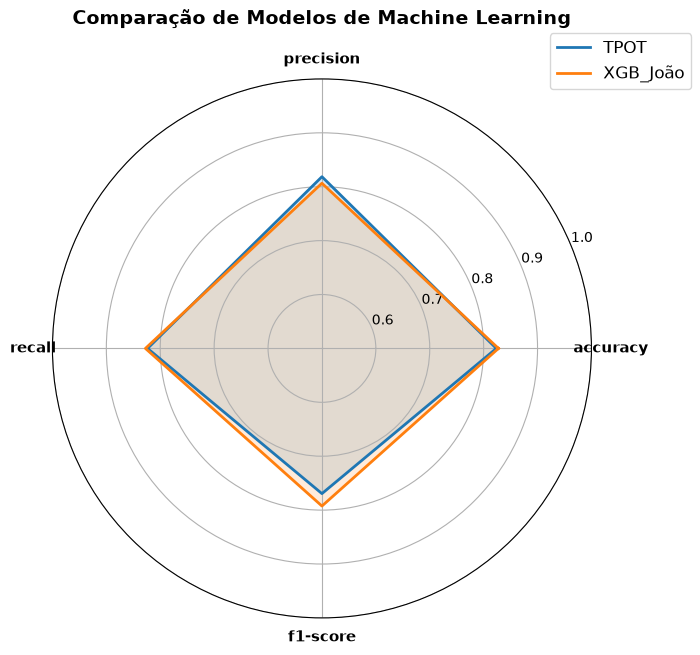

In [36]:
categorias = list(dados["TPOT"].keys())
num_categorias = len(categorias)

angulos = np.linspace(0, 2 * np.pi, num_categorias, endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

cores = {"TPOT": "#1f77b4", "XGB_João": "#ff7f0e"}

for modelo, metricas in dados.items():
    
    valores = [metricas[cat] for cat in categorias]
    
    valores += valores[:1]
    
    
    ax.plot(angulos, valores, linewidth=2, label=modelo, color=cores[modelo])
    ax.fill(angulos, valores, alpha=0.15, color=cores[modelo])


ax.set_xticks(angulos[:-1])
ax.set_xticklabels(categorias, fontsize=11, fontweight='bold')


ax.set_ylim(0.50, 1.0)  


plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)


plt.title("Comparação de Modelos de Machine Learning", fontsize=14, pad=20, fontweight='bold')
plt.show()


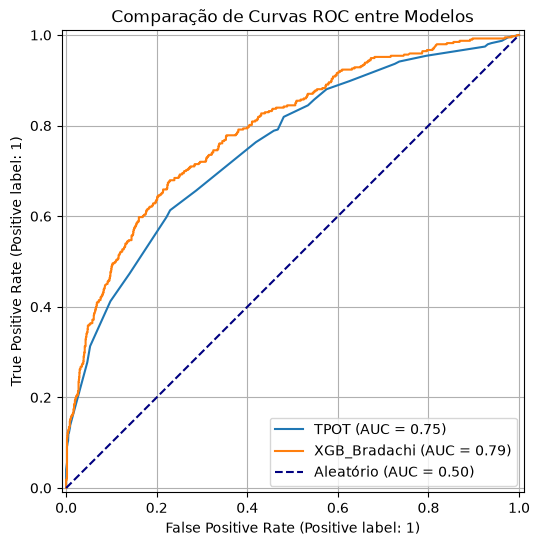

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(modelo_pipeline_tpot, X_teste_tpot, y_teste, ax=ax, name='TPOT')
RocCurveDisplay.from_estimator(modelo_pipeline, X_teste_xgb, y_teste, ax=ax, name='XGB_Bradachi')

# 6. Personalizar o gráfico
ax.plot([0, 1], [0, 1], linestyle='--', color='navy', label='Aleatório (AUC = 0.50)')
ax.set_title('Comparação de Curvas ROC entre Modelos')
ax.legend(loc='lower right')
ax.grid(True)

# 7. Exibir o gráfico
plt.show()

# Conclusão

Nesse trabalho aprendi a usar a biblioteca de auto-ML TPOT. Ela é uma excelente ferramenta para fazer uma exploração inicial de quais parametros, transformações e modelos podemos aplicar para resolver um problema. Sua execução é demorada, mas nos mostra um panorama inicial do que fazer com os dados. 

Um resultado curioso foi que, mesmo com 3 horas de execução, as soluções do TPOT não obteve um resultado superior quanto a minha solução apresentada na atividade 3 (observado ao comparar as métricas de acurácia, f1-score, revocação e precisão para uma parcela do dataset separada para validação). Porém, apesar de não obter um resultado superior, as métricas padrões foram bem próximas. Vale ressaltar que mesmo as métricas sendo próximas, houve uma diferença na curva ROC: o XGB proposto na atividade3 obteve um resultado superior.